# Pick 10 outperforming cryptos from that 200 buckets in the last month, buy and hold it for the next month. Rebalancing monthly, 10% each stock.


In [1]:
!pip install --upgrade binance-historical-data plotly -q
!pip install requests

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.6/9.6 MB 57.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 272.8/272.8 kB 18.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 46.9 MB/s eta 0:00:00


In [6]:
import os
import warnings
import numpy as np
import pandas as pd
import yfinance as yf
from binance_historical_data import BinanceDataDumper
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from datetime import datetime, timedelta, date, time
warnings.filterwarnings('ignore')

In [3]:
def get_list_all_trading_pairs():
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency="1h",
    )
    return data_dumper.get_list_all_trading_pairs()

def filter_usdt_tickers(tickers):
    exclude_keywords = ["UPUSDT", "DOWNUSDT", "BEARUSDT", "BULLUSDT"]
    return [ticker for ticker in tickers if ticker.endswith("USDT") and not any(ex in ticker for ex in exclude_keywords)]

def find_first_data_date(ticker):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency="1h",
    )
    return data_dumper.get_min_start_date_for_ticker(ticker)

def format_time(seconds):
    hours = int(seconds // 3600)
    minutes = int((seconds % 3600) // 60)
    secs = int(seconds % 60)
    return f"{hours:02d}:{minutes:02d}:{secs:02d}"

def detect_timestamp_unit(timestamp):
    num_digits = len(str(timestamp))
    if num_digits == 13:
        return 'ms'
    elif num_digits == 16:
        return 'us'
    else:
        raise ValueError(f"Timestamp không hợp lệ: {timestamp}")

def convert_timestamp(timestamp):
    unit = detect_timestamp_unit(timestamp)
    return pd.to_datetime(timestamp, unit=unit, errors='coerce')

def download_ticker(ticker, date_start, date_end, data_frequency="1h"):
    data_dumper = BinanceDataDumper(
        path_dir_where_to_dump=".",
        asset_class="spot",
        data_type="klines",
        data_frequency= data_frequency,
    )
    date_start = datetime.strptime(date_start, "%Y-%m-%d").date()
    date_end = datetime.strptime(date_end, "%Y-%m-%d").date()
    data_dumper.dump_data(
        tickers = ticker,
        date_start = date_start,
        date_end = date_end,
        is_to_update_existing = False,
    )

def read_csv_file(file_path):
    df = pd.read_csv(file_path)
    df.columns = [
        "open_time", "Open", "High", "Low", "Close", "volume",
        "close_time", "quote_asset_volume", "number_of_trades",
        "taker_buy_base_asset_volume", "taker_buy_quote_asset_volume", "ignore"
    ]
    df['open_time'] = df['open_time'].apply(convert_timestamp)
    df['close_time'] = df['close_time'].apply(convert_timestamp)
    return df

def get_csv_files(directory):
    try:
        if not os.path.exists(directory):
            print(f"Warning: Thư mục không tồn tại: {directory}")
            return []
        return [os.path.join(directory, f) for f in os.listdir(directory) if f.endswith('.csv')]
    except Exception as e:
        print(f"Lỗi khi đọc thư mục {directory}: {str(e)}")
        return []

# Load data from file
def process_csv_files(ticker, data_frequency = "1h"):
    daily_path = os.path.join(os.getcwd(), f"spot/daily/klines/{ticker}/{data_frequency}")
    monthly_path = os.path.join(os.getcwd(), f"spot/monthly/klines/{ticker}/{data_frequency}")
    daily_files = get_csv_files(daily_path)
    monthly_files = get_csv_files(monthly_path)
    all_files = daily_files + monthly_files
    if not all_files:
        print(f"❗ Không có file CSV nào cho {ticker}")
        return None
    data = pd.concat([read_csv_file(file) for file in all_files], ignore_index=True)
    data.sort_values(by='open_time', inplace=True)
    return data

In [4]:
basket = [
    'BTC-USD', 'ETH-USD', 'BNB-USD', 'SOL-USD', 'XRP-USD', 'DOGE-USD', 'ADA-USD',
    'AVAX-USD', 'SHIB-USD', 'DOT-USD', 'TRX-USD', 'WBTC-USD', 'LINK-USD', 'MATIC-USD', 'NEAR-USD',
    'UNI-USD', 'LTC-USD', 'BCH-USD', 'ICP-USD', 'LEO-USD', 'DAI-USD', 'ATOM-USD', 'APT-USD',
    'STX-USD', 'ETC-USD', 'XMR-USD', 'OKB-USD', 'IMX-USD', 'FIL-USD', 'HBAR-USD', 'CRO-USD',
    'INJ-USD', 'ARB-USD', 'MKR-USD', 'RUNE-USD', 'RETH-USD', 'RNDR-USD', 'LDO-USD', 'VET-USD',
    'FDUSD-USD', 'TIA-USD', 'TAO-USD', 'XLM-USD', 'THETA-USD', 'SUI-USD', 'AAVE-USD', 'PEPE-USD',
    'QNT-USD', 'FLOW-USD', 'GRT-USD', 'EGLD-USD', 'AXS-USD', 'MNT-USD', 'USDD-USD', 'ORDI-USD',
    'BGB-USD', 'BSV-USD', 'FET-USD', 'SNX-USD', 'FTM-USD', 'NEO-USD', 'KAS-USD', 'KCS-USD',
    'MINA-USD', 'PAXG-USD', 'CRV-USD', 'DYDX-USD', 'LUNC-USD', 'GT-USD', 'XEC-USD', 'WOO-USD',
    'NXRA-USD', 'GALA-USD', 'WLD-USD', 'OMNI-USD', 'BAT-USD', 'ZEC-USD', 'COMP-USD', 'ZRX-USD',
    '1INCH-USD', 'MASK-USD', 'ENJ-USD', 'CELO-USD', 'KSM-USD', 'AGIX-USD', 'YFI-USD', 'BLUR-USD',
    'CHZ-USD', 'BAND-USD', 'HOT-USD', 'OCEAN-USD', 'SAND-USD', 'MANA-USD', 'ALGO-USD', 'ILV-USD',
    'ANKR-USD', 'RLC-USD', 'ZEN-USD', 'CKB-USD', 'NEXO-USD', 'SKL-USD', 'IOST-USD', 'FLUX-USD',
    'BAL-USD', 'JOE-USD', 'GLM-USD', 'LSK-USD', 'STORJ-USD', 'PLA-USD', 'CVC-USD', 'RIF-USD',
    'DGB-USD', 'LRC-USD', 'QKC-USD', 'MX-USD', 'POLYX-USD', 'UMA-USD', 'AMP-USD', 'XNO-USD',
    'DENT-USD', 'ARK-USD', 'ARDR-USD', 'STMX-USD', 'TRAC-USD', 'PUNDIX-USD', 'HNT-USD', 'XVS-USD',
    'CHR-USD', 'MTL-USD', 'SFP-USD', 'IDEX-USD', 'COTI-USD', 'BNT-USD', 'TOMO-USD', 'BICO-USD',
    'FLOKI-USD', 'VRA-USD', 'SYS-USD', 'WIN-USD', 'ELF-USD', 'FIO-USD', 'SLP-USD', 'REQ-USD',
    'PRO-USD', 'UOS-USD', 'ADX-USD', 'LOOM-USD', 'POWR-USD', 'DODO-USD', 'MLN-USD', 'PHA-USD',
    'TLM-USD', 'CTXC-USD', 'MOB-USD', 'NMR-USD', 'PERL-USD', 'ARPA-USD', 'TVK-USD', 'STRAX-USD',
    'NKN-USD', 'STPT-USD', 'TRB-USD', 'MBL-USD', 'BTS-USD', 'WTC-USD', 'VITE-USD', 'XVG-USD',
    'C98-USD', 'VIB-USD', 'FORTH-USD', 'ALICE-USD', 'OXT-USD', 'KMD-USD', 'GTC-USD', 'FIS-USD',
    'AST-USD', 'WAXP-USD', 'DOCK-USD', 'BEL-USD', 'TWT-USD', 'REI-USD', 'DF-USD', 'AERGO-USD',
    'SNT-USD', 'NAV-USD', 'NAS-USD', 'DNT-USD', 'ELA-USD', 'GRS-USD', 'NULS-USD', 'XEM-USD',
    'STEEM-USD', 'BAN-USD', 'SC-USD', 'RDD-USD', 'GAME-USD', 'BTG-USD', 'BURGER-USD', 'GNO-USD',
    'BEAM-USD', 'MDT-USD', 'TROY-USD', 'SOLO-USD', 'TRVL-USD', 'XRD-USD', 'OAX-USD', 'DEXE-USD'
    ]


In [15]:
def download_data(basket, start_date, end_date):
    data = {}
    data = yf.download(basket, start=start_date, end=end_date, auto_adjust=False)['Close']
    return data

# basket = ["USDT-USD", "PAXG-USD", "BTC-USD"]

end_date = date.today() - timedelta(days=1)
# end_date = date.fromisoformat("2025-01-01")
start_date = end_date - timedelta(days=365)
# end_date = end_date.strftime("%Y-%m-%d")
df = download_data(basket, start_date, end_date)

[*********************100%***********************]  207 of 207 completed
ERROR:yfinance:
12 Failed downloads:
ERROR:yfinance:['TVK-USD', 'SUI-USD', 'COMP-USD', 'REI-USD', 'IMX-USD', 'TAO-USD', 'RNDR-USD', 'GRT-USD', 'MNT-USD', 'MASK-USD', 'PEPE-USD', 'PLA-USD']: YFPricesMissingError('possibly delisted; no price data found  (1d 2024-08-05 -> 2025-08-05)')


In [16]:
df

Ticker,1INCH-USD,AAVE-USD,ADA-USD,ADX-USD,AERGO-USD,AGIX-USD,ALGO-USD,ALICE-USD,AMP-USD,ANKR-USD,...,XMR-USD,XNO-USD,XRD-USD,XRP-USD,XVG-USD,XVS-USD,YFI-USD,ZEC-USD,ZEN-USD,ZRX-USD
Date,,,,,,,,,,,,,,,,,,,,,
2024-08-05,0.253099,96.076225,0.313155,0.139151,0.076094,0.391087,0.110250,0.803649,0.003267,0.023150,...,145.731491,0.735899,0.023173,0.489466,0.003040,5.507068,4883.644043,30.156370,7.597435,0.261274
2024-08-06,0.260849,103.635384,0.330782,0.140558,0.081047,0.521872,0.112588,0.846391,0.003432,0.024284,...,147.792297,0.773882,0.024849,0.505697,0.003207,5.690789,4997.657715,31.807383,7.821367,0.278852
2024-08-07,0.249925,98.283943,0.323698,0.137178,0.080083,0.370940,0.109672,0.825334,0.003349,0.023213,...,145.929733,0.774177,0.024832,0.600810,0.003123,5.652650,4865.364746,32.393429,7.675242,0.277147
2024-08-08,0.277610,101.681480,0.351814,0.149172,0.087988,0.389586,0.122318,0.916072,0.003683,0.025740,...,158.227325,0.866445,0.027440,0.617577,0.003625,6.530533,5180.181641,35.912113,8.291549,0.308128
2024-08-09,0.274963,96.503120,0.348547,0.148273,0.089660,0.372552,0.120169,0.910774,0.003648,0.025612,...,153.080399,0.918018,0.027782,0.581153,0.003728,6.427936,5105.468750,40.784222,8.552248,0.307074
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-07-30,0.264448,274.236389,0.763439,0.128282,0.123144,0.298450,0.253662,0.402498,0.003687,0.016341,...,308.445343,0.968246,0.004457,3.098376,0.006586,6.252835,5452.687012,38.410477,8.257016,0.252205
2025-07-31,0.249525,261.052216,0.740060,0.125112,0.117905,0.291120,0.244303,0.375277,0.003599,0.016101,...,306.287018,0.905027,0.003939,3.025170,0.006204,6.081713,5207.929199,36.965919,7.930458,0.237166
2025-08-01,0.242088,255.845184,0.715667,0.122014,0.114711,0.276861,0.236607,0.365747,0.003432,0.015400,...,297.235626,0.884151,0.003905,2.964597,0.006002,5.827675,5087.570312,35.897881,7.527027,0.231364


In [17]:
pct_data = df.pct_change()

if 'monthly_pnl' in pct_data.columns:
    pct_data = pct_data.drop('monthly_pnl', axis=1)

current = []
total_pnls = [0,0]
for i in range(2, len(pct_data)):
    last_month = pct_data.index[i-1]
    current_month = pct_data.index[i]
    top_10 = pct_data.loc[last_month].dropna().sort_values(ascending=False).head(10)
    print(f"Top 10 tickers for {last_month}: {top_10.index.tolist()}")
    for top_ticker in top_10.index:
        current.append(pct_data.loc[current_month, top_ticker])
    total_pnls.append(np.mean(current))
    current = []

pct_data['monthly_pnl'] = total_pnls
pct_data = pct_data.fillna(0)
pct_data

Top 10 tickers for 2024-08-06 00:00:00: ['AGIX-USD', 'TRB-USD', 'UMA-USD', 'XEM-USD', 'ORDI-USD', 'COTI-USD', 'DOCK-USD', 'CKB-USD', 'DNT-USD', 'SOL-USD']
Top 10 tickers for 2024-08-07 00:00:00: ['WTC-USD', 'OMNI-USD', 'XRP-USD', 'SOLO-USD', 'XLM-USD', 'SNT-USD', 'MOB-USD', 'GTC-USD', 'STRAX-USD', 'GAME-USD']
Top 10 tickers for 2024-08-08 00:00:00: ['RDD-USD', 'QKC-USD', 'NXRA-USD', 'HNT-USD', 'INJ-USD', 'WLD-USD', 'CKB-USD', 'RIF-USD', 'XVG-USD', 'DODO-USD']
Top 10 tickers for 2024-08-09 00:00:00: ['QKC-USD', 'HNT-USD', 'ZEC-USD', 'CRO-USD', 'ARDR-USD', 'GTC-USD', 'XEM-USD', 'ARK-USD', 'XNO-USD', 'MTL-USD']
Top 10 tickers for 2024-08-10 00:00:00: ['RDD-USD', 'LUNC-USD', 'CTXC-USD', 'LSK-USD', 'INJ-USD', 'PERL-USD', 'OCEAN-USD', 'ARK-USD', 'FET-USD', 'BTS-USD']
Top 10 tickers for 2024-08-11 00:00:00: ['WTC-USD', 'AGIX-USD', 'OMNI-USD', 'GLM-USD', 'STX-USD', 'MLN-USD', 'LEO-USD', 'NAV-USD', 'PRO-USD', 'DOCK-USD']
Top 10 tickers for 2024-08-12 00:00:00: ['CRV-USD', 'ORDI-USD', 'HNT-USD',

Ticker,1INCH-USD,AAVE-USD,ADA-USD,ADX-USD,AERGO-USD,AGIX-USD,ALGO-USD,ALICE-USD,AMP-USD,ANKR-USD,...,XNO-USD,XRD-USD,XRP-USD,XVG-USD,XVS-USD,YFI-USD,ZEC-USD,ZEN-USD,ZRX-USD,monthly_pnl
Date,,,,,,,,,,,,,,,,,,,,,
2024-08-05,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
2024-08-06,0.030620,0.078679,0.056288,0.010111,0.065091,0.334414,0.021206,0.053185,0.050505,0.048985,...,0.051614,0.072325,0.033161,0.054934,0.033361,0.023346,0.054748,0.029475,0.067278,0.000000
2024-08-07,-0.041879,-0.051637,-0.021416,-0.024047,-0.011894,-0.289213,-0.025900,-0.024879,-0.024184,-0.044103,...,0.000381,-0.000684,0.188083,-0.026193,-0.006702,-0.026471,0.018425,-0.018683,-0.006114,-0.073074
2024-08-08,0.110773,0.034569,0.086859,0.087434,0.098710,0.050267,0.115307,0.109941,0.099731,0.108861,...,0.119182,0.105026,0.027907,0.160743,0.155305,0.064706,0.108623,0.080298,0.111785,0.032863
2024-08-09,-0.009535,-0.050927,-0.009286,-0.006027,0.019003,-0.043723,-0.017569,-0.005783,-0.009503,-0.004973,...,0.059523,0.012464,-0.058979,0.028414,-0.015710,-0.014423,0.135668,0.031442,-0.003421,0.037984
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2025-07-30,-0.033263,-0.027713,-0.024319,0.009681,-0.008319,-0.027869,-0.026253,-0.003952,-0.014435,-0.014118,...,-0.003457,0.036512,-0.009607,-0.017455,-0.019187,-0.000495,-0.049979,-0.012665,-0.019150,-0.002830
2025-07-31,-0.056431,-0.048076,-0.030623,-0.024711,-0.042544,-0.024560,-0.036896,-0.067630,-0.023868,-0.014687,...,-0.065292,-0.116222,-0.023627,-0.058002,-0.027367,-0.044888,-0.037608,-0.039549,-0.059630,-0.068530
2025-08-01,-0.029805,-0.019946,-0.032961,-0.024762,-0.027090,-0.048980,-0.031502,-0.025395,-0.046402,-0.043538,...,-0.023067,-0.008632,-0.020023,-0.032560,-0.041771,-0.023111,-0.028893,-0.050871,-0.024464,-0.035404


In [18]:
sharpe_ratio = np.mean(total_pnls) / np.std(total_pnls)
print(f"Sharpe Ratio: {sharpe_ratio}")

Sharpe Ratio: -0.033845760924070184


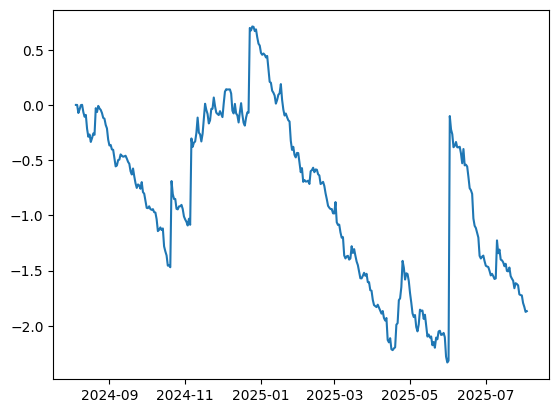

In [20]:
dates = pct_data.index
# spy = data['SPY']
# Plot profit
plt.plot(dates, np.cumsum(total_pnls))
#plt.plot(dates,np.cumprod(1+np.array(total_pnls)),'-o')
# plt.plot(dates,np.cumprod(1+np.array(total_pnls)),color = 'blue')
# plt.plot(dates,np.cumprod(1+np.array(spy)),color = 'orange')
#plt.plot(dates, np.cumsum(total_pnls))

In [ ]:
# data_frequency = '15m'
# data = pd.DataFrame()


# # List of companies
# for ticker in basket:
#     download_ticker(ticker, "2025-04-01", "2025-06-30", data_frequency)
#     ticker_data = process_csv_files(ticker, data_frequency)
#     if ticker_data is None:
#         continue
#     price = ticker_data['Close']
#     data[f'{ticker}'] = price

# data = data.set_index(ticker_data['open_time'])
# data

---> Found overall tickers: 592
---> Filter to asked tickers: 7
------> Tickers left: 2
Download full data for 2 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 1d
---> Start Date: 20250101
---> End Date: 20250725


Tickers:   0%|          | 0/2 [00:00<?, ?it/s]

monthly files to download: 0files [00:00, ?files/s]

daily files to download: 0files [00:00, ?files/s]

monthly files to download: 0files [00:00, ?files/s]

...

Tickers: 0it [00:00, ?it/s]

Tried to dump data for 0 tickers:
❗ Không có file CSV nào cho GNOUSDT
---> Found overall tickers: 592
---> Filter to asked tickers: 8
------> Tickers left: 0
Download full data for 0 tickers: 
---> Data will be saved here: /content/spot
---> Data Frequency: 1d
---> Start Date: 20250101
---> End Date: 20250725


Tickers: 0it [00:00, ?it/s]

Tried to dump data for 0 tickers:
❗ Không có file CSV nào cho BEAMUSDT


TypeError: 'NoneType' object is not subscriptable